In [1]:
# Keep imports and data/output paths relative to the repository root.
import os
import sys
from pathlib import Path
from datetime import datetime
from uuid import uuid4

for repository_dir in (Path("."), Path(".."), Path("../.."), Path("../../..")):
    if (repository_dir / "src" / "use_croma.py").is_file():
        os.chdir(repository_dir)
        break
else:
    raise FileNotFoundError("Open this notebook from inside the repository.")
if "src" not in sys.path:
    sys.path.insert(0, "src")

EXPERIMENT_NAME = "croma_sen1floods11/original_S2"
NOTEBOOK_PATH = "experiments/croma_sen1floods11/original_S2/02_croma_on_sen1floods11_test_s2.ipynb"


In [2]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as FT
import torch.nn.functional as F
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import csv
import random
import math
import json
import pandas as pd

from PIL import Image
from pathlib import Path
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models.segmentation.fcn import FCNHead
from use_croma import PretrainedCROMA
from IPython.display import display
from segmentation_metrics import binary_metrics, metric_table


In [3]:
# Optical-only helpers live here to keep this experiment self-contained.
# Reference: https://github.com/antofuller/CROMA#using-pretrained-croma-models
CROP_SIZE = 120
IGNORE_INDEX = 255
SCHEMA = "croma_s2_fcn_v1"
S2_BANDS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 13]  # Rasterio indices; omit B10/cirrus.
PREPROCESSING = {
    "modality": "optical", "bands": S2_BANDS,
    "band_names": ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12"],
    "normalization": "per_full_image_band_mean_plus_minus_2std_float_0_1",
    "statistics": "finite_non_nodata_pixels", "invalid_input_fill_after_normalization": 0,
    "ignore_index": IGNORE_INDEX,
}
SEED = 234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

def load_split_paths(csv_file, x_dir, y_dir):
    pairs = []
    with open(csv_file, newline="") as handle:
        for x_name, y_name in csv.reader(handle):
            chip = x_name.strip().removesuffix("_S1Hand.tif")
            if y_name.strip() != chip + "_LabelHand.tif":
                raise ValueError(f"Mismatched split row: {x_name}, {y_name}")
            x_path, y_path = Path(x_dir) / (chip + "_S2Hand.tif"), Path(y_dir) / y_name.strip()
            if not x_path.is_file() or not y_path.is_file():
                raise FileNotFoundError(f"Missing pair: {x_path}, {y_path}")
            with rasterio.open(x_path) as x, rasterio.open(y_path) as y:
                if (x.count != 13 or x.shape != y.shape or x.crs != y.crs
                        or not x.transform.almost_equals(y.transform, precision=1e-10)):
                    raise ValueError(f"Band/grid mismatch: {chip}")
            pairs.append((x_path, y_path))
    return pairs

def load_image_pair(pair):
    with rasterio.open(pair[0]) as src:
        image = src.read(S2_BANDS, out_dtype="float32", masked=True).filled(np.nan)
    with rasterio.open(pair[1]) as src:
        mask = src.read(1).astype(np.int64)
    return image, mask

def prepare_sample(data):
    raw, mask = data
    image = torch.as_tensor(raw, dtype=torch.float32)
    mask = torch.as_tensor(mask, dtype=torch.long).clone()
    mask[mask == -1] = IGNORE_INDEX
    if image.shape[0] != 12 or image.shape[-2:] != mask.shape:
        raise ValueError("Expected aligned 12-band optical image and label.")
    if not set(torch.unique(mask).tolist()).issubset({0, 1, IGNORE_INDEX}):
        raise ValueError("Unexpected label values.")
    normalized = torch.zeros_like(image)
    # CROMA's float normalization, applied per full image before cropping/tiling.
    # Exclude nodata from statistics; handle empty/constant channels explicitly.
    for band in range(12):
        valid = torch.isfinite(image[band])
        values = image[band][valid]
        if values.numel() < 2:
            continue
        mean, std = values.mean(), values.std()
        if std > 1e-6:
            normalized[band][valid] = ((values - (mean - 2 * std)) / (4 * std)).clamp(0, 1)
        else:
            normalized[band][valid] = 0.5
    return normalized, mask

class Sen1Floods11Dataset(Dataset):
    def __init__(self, data_list, preprocess_func):
        self.data_list, self.preprocess_func = data_list, preprocess_func
    def __len__(self):
        return len(self.data_list)
    def __getitem__(self, index):
        return self.preprocess_func(load_image_pair(self.data_list[index]))

class CROMAFloodSegmentation(nn.Module):
    def __init__(self, croma, head):
        super().__init__()
        self.croma, self.head = croma, head
    def train(self, mode=True):
        super().train(mode)
        self.croma.eval()
        return self
    def forward(self, images):
        with torch.no_grad():
            features = self.croma(optical_images=images)["optical_encodings"]
        batch, tokens, channels = features.shape
        side = int(tokens ** 0.5)
        assert side * side == tokens
        features = features.transpose(1, 2).reshape(batch, channels, side, side)
        return F.interpolate(self.head(features), size=images.shape[-2:],
                             mode="bilinear", align_corners=False)


#### **First things first**


In [4]:
model_name = "croma_large_s2_fcn_weighted_ce.pt"


In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
pretrained_path = "pretrained/CROMA_large.pt"
path_to_the_dataset = "dataset/sen1floods11_hand_labeled_only/HandLabeled/"
path_to_the_dataset_index = "dataset/sen1floods11_hand_labeled_only/flood_handlabeled/"
path_to_X = path_to_the_dataset + "S2Hand/"
path_to_Y = path_to_the_dataset + "LabelHand/"
path_to_test_csv = path_to_the_dataset_index + "flood_test_data.csv"
path_to_test_bolivia_csv = path_to_the_dataset_index + "flood_bolivia_data.csv"


#### **Functions**

In [6]:

def preprocess_test(data):
   
    return prepare_sample(data)

#### **Creating datasets**

In [7]:

# Preserve official split membership and order, including fully ignored/empty scenes.
split_files = {"train": "flood_train_data.csv", "valid": "flood_valid_data.csv",
               "non_bol": "flood_test_data.csv", "bol": "flood_bolivia_data.csv"}
expected_counts = {"train": 252, "valid": 89, "non_bol": 90, "bol": 15}
all_splits = {name: load_split_paths(Path(path_to_the_dataset_index) / filename, path_to_X, path_to_Y)
              for name, filename in split_files.items()}
for name, pairs in all_splits.items():
    assert len(pairs) == expected_counts[name], (name, len(pairs))
    assert len({x.stem for x, _ in pairs}) == len(pairs), f"Duplicates in {name}"
for i, name in enumerate(all_splits):
    for other in list(all_splits)[i+1:]:
        assert not ({x.stem for x, _ in all_splits[name]} & {x.stem for x, _ in all_splits[other]})
print("Verified S2/label grids and disjoint split counts:", {k: len(v) for k, v in all_splits.items()})

test_data_non_bolivia = all_splits["non_bol"]
test_data_bolivia = all_splits["bol"]


Verified S2/label grids and disjoint split counts: {'train': 252, 'valid': 89, 'non_bol': 90, 'bol': 15}


In [8]:
print(f"Non bolivia test samples: {len(test_data_non_bolivia)}")
print(f"Bolivia test samples: {len(test_data_bolivia)}")

Non bolivia test samples: 90
Bolivia test samples: 15


In [9]:
print(test_data_non_bolivia[0])
print(test_data_bolivia[0])

(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S2Hand/Ghana_313799_S2Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Ghana_313799_LabelHand.tif'))
(WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/S2Hand/Bolivia_103757_S2Hand.tif'), WindowsPath('dataset/sen1floods11_hand_labeled_only/HandLabeled/LabelHand/Bolivia_103757_LabelHand.tif'))


In [10]:
test_dataset_non_bolivia = Sen1Floods11Dataset(
 data_list = test_data_non_bolivia,
 preprocess_func=preprocess_test
)

test_dataset_bolivia = Sen1Floods11Dataset(
 data_list = test_data_bolivia,
 preprocess_func=preprocess_test
)

In [11]:
test_loader_non_bolivia = DataLoader(
    test_dataset_non_bolivia,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader_bolivia = DataLoader(
    test_dataset_bolivia,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

#### **Model**

In [12]:
croma = PretrainedCROMA(pretrained_path= pretrained_path, 
                        size='large', 
                        modality='optical', 
                        image_resolution=120)

croma = croma.to(device)

Initializing optical encoder


In [13]:
croma.requires_grad_(False) # Freeze the weights of CROMA
croma.eval()

PretrainedCROMA(
  (s2_encoder): ViT(
    (linear_input): Linear(in_features=768, out_features=1024, bias=True)
    (transformer): BaseTransformer(
      (layers): ModuleList(
        (0-23): 24 x ModuleList(
          (0): Attention(
            (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
            (to_out): Linear(in_features=1024, out_features=1024, bias=True)
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=0.0, inplace=False)
          )
          (1): FFN(
            (net): Sequential(
              (0): Linear(in_features=1024, out_features=4096, bias=True)
              (1): GELU(approximate='none')
              (2): Dropout(p=0.0, inplace=False)
              (3): Linear(in_features=4096, out_features=1024, bias=True)
            )
            (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
          )
        )
      )
      (norm_out): LayerNo

#### **Creating the head**

In [14]:
head = FCNHead(in_channels=1024, channels=2)

head[1] = nn.GroupNorm(
    num_groups=16,
    num_channels=256
)

head = head.to(device)

In [15]:
# None selects the latest completed optical FCN run; an explicit path is also supported.
checkpoint_path = None
if checkpoint_path is None:
    candidates = []
    for folder in (Path("runs") / EXPERIMENT_NAME).glob("train_*"):
        config_path, history_path = folder / "run.json", folder / "croma_training_history.json"
        if not config_path.exists() or not history_path.exists():
            continue
        config = json.loads(config_path.read_text())
        history = json.loads(history_path.read_text())
        candidate = folder / model_name
        if (config.get("schema") == SCHEMA and config.get("preprocessing") == PREPROCESSING
                and history.get("epochs_completed") == config.get("epochs") and candidate.exists()):
            candidates.append(candidate)
    if not candidates:
        raise FileNotFoundError("Complete the original_S2 training notebook first, or set checkpoint_path.")
    checkpoint_path = max(candidates, key=lambda p: p.parent.name)
checkpoint_path = Path(checkpoint_path)
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
if checkpoint.get("schema") != SCHEMA or checkpoint.get("preprocessing") != PREPROCESSING:
    raise ValueError("Checkpoint is not compatible with this optical FCN experiment.")
head.load_state_dict(checkpoint["head_state_dict"], strict=True)
print(f"Loaded optical FCN: {checkpoint_path}, epoch {checkpoint['epoch']}")


Loaded optical FCN: runs\croma_sen1floods11\original_S2\train_croma_large_s2_fcn_weighted_ce_2026-10-22_23-32-07_277161_800eae90\croma_large_s2_fcn_weighted_ce.pt, epoch 60


In [16]:
model = CROMAFloodSegmentation(croma, head).to(device)
model.eval()

CROMAFloodSegmentation(
  (croma): PretrainedCROMA(
    (s2_encoder): ViT(
      (linear_input): Linear(in_features=768, out_features=1024, bias=True)
      (transformer): BaseTransformer(
        (layers): ModuleList(
          (0-23): 24 x ModuleList(
            (0): Attention(
              (to_qkv): Linear(in_features=1024, out_features=3072, bias=False)
              (to_out): Linear(in_features=1024, out_features=1024, bias=True)
              (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (1): FFN(
              (net): Sequential(
                (0): Linear(in_features=1024, out_features=4096, bias=True)
                (1): GELU(approximate='none')
                (2): Dropout(p=0.0, inplace=False)
                (3): Linear(in_features=4096, out_features=1024, bias=True)
              )
              (input_norm): LayerNorm((1024,), eps=1e-05, elementwise_affine

In [17]:
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor([1.0, 8.0], device=device),
    ignore_index=IGNORE_INDEX
)

In [18]:
@torch.inference_mode()
def sliding_window_logits(
    model,
    image,
    device,
    tile_size=120,
    stride=60,
    tile_batch_size=8
):
    """
    Predict segmentation logits for one complete image.

    Parameters
    ----------
    model:
        Frozen CROMA + trained FCN head.

    image:
        Tensor [12, H, W], already normalized.

    device:
        CUDA or CPU.

    tile_size:
        Spatial size of each CROMA input (120).

    stride:
        Distance between consecutive windows (60 = 50% overlap).

    tile_batch_size:
        Number of windows processed simultaneously.

    Returns
    -------
    logits:
        Tensor [2, H, W] on CPU.
    """

    model.eval()

    C, H, W = image.shape

    assert C == 12
    assert H >= tile_size and W >= tile_size
    assert 0 < stride <= tile_size

    # Generate starting positions along one dimension
    def get_starts(length):
        starts = list(
            range(0, length - tile_size + 1, stride)
        )

        # Ensure the final window reaches the image boundary
        if starts[-1] != length - tile_size:
            starts.append(length - tile_size)

        return starts

    # All window coordinates
    positions = [
        (top, left)
        for top in get_starts(H)
        for left in get_starts(W)
    ]

    # Accumulate predictions and coverage counts
    logits_sum = torch.zeros((2, H, W), dtype=torch.float32)
    counts = torch.zeros((H, W), dtype=torch.float32)

    # Process windows in batches
    for start in range(0, len(positions), tile_batch_size):

        batch_positions = positions[start:start + tile_batch_size]

        # Extract tiles
        tiles = torch.stack([
            image[:, top:top + tile_size, left:left + tile_size]
            for top, left in batch_positions
        ])

        tiles = tiles.to(device)

        # Run frozen CROMA + FCN head
        outputs = model(tiles).cpu()

        # Place tile predictions back into the full image
        for (top, left), logits in zip(batch_positions, outputs):

            logits_sum[
                :, top:top + tile_size, left:left + tile_size
            ] += logits

            counts[
                top:top + tile_size, left:left + tile_size
            ] += 1

    assert (counts > 0).all(), "Some pixels were not covered."

    # Average logits wherever windows overlap
    return logits_sum / counts.unsqueeze(0)

@torch.inference_mode()
def test(
    model,
    valid_loader,
    criterion,
    device,
    save_predictions=False,
    save_dir=None,
    test_data=None,
    save_metrics=True
):
    model.eval()

    if criterion.reduction != "mean":
        raise ValueError("This implementation expects reduction='mean'.")

    save_dir = run_results_dir / "test" if save_dir is None else Path(save_dir)

    if save_predictions:
        if test_data is None:
            raise ValueError("Provide test_data to save georeferenced predictions.")

        if not hasattr(valid_loader.dataset, "data_list"):
            raise ValueError("Expected a dataset with data_list.")

        if list(test_data) != list(valid_loader.dataset.data_list):
            raise ValueError("test_data must match the dataset order.")

        if valid_loader.batch_size != 1:
            raise ValueError("Use batch_size=1 to save predictions.")

        if not isinstance(
            valid_loader.sampler,
            torch.utils.data.SequentialSampler
        ):
            raise ValueError("Use shuffle=False when saving predictions.")

    if save_predictions or save_metrics:
        save_dir.mkdir(parents=True, exist_ok=True)

    total_loss = 0.0
    total_weight = 0.0

    TP = FP = FN = TN = 0
    sample_idx = 0

    for images, masks in valid_loader:

        for image, mask in zip(images, masks):

            mask = mask.cpu().long()
            valid = mask != IGNORE_INDEX
            n_valid = valid.sum().item()

            # Full-image sliding-window inference
            logits = sliding_window_logits(
                model,
                image,
                device,
                tile_size=CROP_SIZE,
                stride=CROP_SIZE // 2,
                tile_batch_size=8
            )

            prediction = logits.argmax(dim=0)

            # Save georeferenced prediction
            if save_predictions:

                x_path, y_path = test_data[sample_idx]
                x_path = Path(x_path)

                output_path = (
                    save_dir / f"{x_path.stem}_prediction.tif"
                )

                with rasterio.open(y_path) as src:
                    profile = src.profile.copy()

                profile.update(
                    driver="GTiff",
                    count=1,
                    dtype="uint8",
                    nodata=None
                )

                pred_np = prediction.numpy().astype(np.uint8)

                with rasterio.open(output_path, "w", **profile) as dst:
                    dst.write(pred_np, 1)

            sample_idx += 1

            # Ignore samples without any valid ground-truth pixels
            if n_valid == 0:
                continue

            # Compute loss on the criterion's device
            logits_device = logits.unsqueeze(0).to(device)
            mask_device = mask.unsqueeze(0).to(device)

            loss = criterion(logits_device, mask_device)

            # Correct aggregation for weighted/unweighted CE
            if criterion.weight is not None:
                image_weight = criterion.weight[
                    mask_device[mask_device != IGNORE_INDEX]
                ].sum().item()
            else:
                image_weight = n_valid

            total_loss += loss.item() * image_weight
            total_weight += image_weight

            # Confusion matrix for the water class
            TP += (
                (prediction == 1) & (mask == 1) & valid
            ).sum().item()

            FP += (
                (prediction == 1) & (mask == 0) & valid
            ).sum().item()

            FN += (
                (prediction == 0) & (mask == 1) & valid
            ).sum().item()

            TN += (
                (prediction == 0) & (mask == 0) & valid
            ).sum().item()

    if total_weight == 0:
        raise RuntimeError("No valid test pixels.")

    def safe_div(numerator, denominator):
        return (
            numerator / denominator
            if denominator > 0
            else float("nan")
        )

    # Segmentation metrics (global / pooled)
    water_iou = safe_div(TP, TP + FP + FN)
    nonwater_iou = safe_div(TN, TN + FP + FN)
    miou = (water_iou + nonwater_iou) / 2

    # Classification metrics for water
    precision = safe_div(TP, TP + FP)
    recall = safe_div(TP, TP + FN)
    f1 = safe_div(2 * TP, 2 * TP + FP + FN)

    # Remote sensing error rates
    omission = safe_div(FN, TP + FN)
    commission = safe_div(FP, TP + FP)

    accuracy = safe_div(TP + TN, TP + TN + FP + FN)

    metrics = {
        "test_loss": total_loss / total_weight,
        "water_iou": water_iou,
        "nonwater_iou": nonwater_iou,
        "miou": miou,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "omission_error": omission,
        "commission_error": commission,
        "accuracy": accuracy,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
    }

    metrics.update(binary_metrics(TP, FP, FN, TN))

    if save_metrics:
        # Use null for undefined metrics in standards-compliant JSON
        json_metrics = {
            k: (
                None
                if isinstance(v, float) and not math.isfinite(v)
                else v
            )
            for k, v in metrics.items()
        }

        with open(save_dir / "metrics.json", "w") as f:
            json.dump(json_metrics, f, indent=4)

    return metrics

In [19]:
# A new directory is created each time this run cell is executed.
run_id = datetime.now().astimezone().strftime("%Y-%m-%d_%H-%M-%S_%f") + "_" + uuid4().hex[:8]
run_results_dir = Path("runs") / EXPERIMENT_NAME / f"test_{checkpoint_path.stem}_{run_id}"
run_results_dir.mkdir(parents=True, exist_ok=False)
print(f"Run directory: {run_results_dir}")

with (run_results_dir / "run.json").open("w", encoding="utf-8") as run_file:
    json.dump({
        "experiment": EXPERIMENT_NAME,
        "model_name": checkpoint_path.stem,
        "phase": "test",
        "run_id": run_id,
        "started_at": datetime.now().astimezone().isoformat(),
        "notebook": NOTEBOOK_PATH,
        "pretrained_weights": pretrained_path,
        "schema": SCHEMA, "preprocessing": PREPROCESSING, "modality": "optical",
        "checkpoint_epoch": checkpoint["epoch"], "split_counts": expected_counts,
    "checkpoint": checkpoint_path.as_posix(),
    }, run_file, indent=4)

metrics_nonbolivia = test(
    model=model,
    valid_loader=test_loader_non_bolivia,
    criterion=criterion,
    device=device,
    save_predictions=True,
    save_dir=run_results_dir / "non_bol",
    test_data=test_data_non_bolivia
)

print("Non Bolivia test: ",metrics_nonbolivia)

Run directory: runs\croma_sen1floods11\original_S2\test_croma_large_s2_fcn_weighted_ce_2026-10-23_00-43-04_428425_867de1f5
Non Bolivia test:  {'test_loss': 0.20249875006343157, 'water_iou': 0.7051035664174239, 'nonwater_iou': 0.9471954970300226, 'miou': 0.8261495317237233, 'precision': 0.7677172227082456, 'recall': 0.8963236443148574, 'f1': 0.8270507203253465, 'omission_error': 0.10367635568514255, 'commission_error': 0.23228277729175437, 'accuracy': 0.9531150366418849, 'TP': 2300057, 'FP': 695912, 'FN': 266044, 'TN': 17255354, 'specificity': 0.9612332634366846, 'false_positive_rate': 0.03876673656331537, 'balanced_accuracy': 0.9287784538757711, 'mcc': 0.8033306342030101, 'ground_truth_water_fraction': 0.1250697031446579, 'predicted_water_fraction': 0.1460211244454515, 'valid_pixels': 20517367}


In [20]:
metrics_bolivia = test(
    model=model,
    valid_loader=test_loader_bolivia,
    criterion=criterion,
    device=device,
    save_predictions=True,
    save_dir=run_results_dir / "bol",
    test_data=test_data_bolivia
)

print("Bolivia test: ", metrics_bolivia)

Bolivia test:  {'test_loss': 0.4361886224105507, 'water_iou': 0.5344547457616037, 'nonwater_iou': 0.8879052691981635, 'miou': 0.7111800074798835, 'precision': 0.6757078469178358, 'recall': 0.7188368391431285, 'f1': 0.6966054192707196, 'omission_error': 0.2811631608568715, 'commission_error': 0.3242921530821642, 'accuracy': 0.9006857136879471, 'TP': 326973, 'FP': 156924, 'FN': 127891, 'TN': 2256027, 'specificity': 0.9349659400460266, 'false_positive_rate': 0.06503405995397338, 'balanced_accuracy': 0.8269013895945776, 'mcc': 0.637734152847241, 'ground_truth_water_fraction': 0.1586099521761341, 'predicted_water_fraction': 0.16873368749378884, 'valid_pixels': 2867815}


In [21]:
def aw_pw_fw_targets(
    path_to_labels,
    path_to_predictions,
    path_to_permanent_water,
):
    labels_dir = Path(path_to_labels)
    predictions_dir = Path(path_to_predictions)
    permanent_dir = Path(path_to_permanent_water)

    suffix = "_S2Hand_prediction.tif"
    prediction_files = sorted(predictions_dir.glob(f"*{suffix}"))

    if not prediction_files:
        raise FileNotFoundError(
            f"No prediction files found in {predictions_dir}"
        )

    for prediction_path in prediction_files:
        chip_id = prediction_path.name.removesuffix(suffix)

        label_path = labels_dir / f"{chip_id}_LabelHand.tif"
        permanent_path = permanent_dir / f"{chip_id}_JRCWaterHand.tif"

        for path in (label_path, permanent_path):
            if not path.is_file():
                raise FileNotFoundError(path)

        with (
            rasterio.open(prediction_path) as pred_src,
            rasterio.open(label_path) as label_src,
            rasterio.open(permanent_path) as perm_src,
        ):
            # Allow tiny floating-point differences in georeferencing.
            for src in (pred_src, perm_src):
                if (
                    src.shape != label_src.shape
                    or src.crs != label_src.crs
                    or not src.transform.almost_equals(
                        label_src.transform, precision=1e-10
                    )
                ):
                    raise ValueError(f"Raster grid mismatch: {chip_id}")

            prediction = pred_src.read(1)
            y = label_src.read(1).astype(np.int16)
            p = perm_src.read(1)

        y[y == -1] = 255

        if not np.isin(prediction, [0, 1]).all():
            raise ValueError(f"Non-binary prediction: {chip_id}")
        if not np.isin(y, [0, 1, 255]).all():
            raise ValueError(f"Unexpected hand labels: {chip_id}")
        if not np.isin(p, [0, 1]).all():
            raise ValueError(f"Unexpected JRC values: {chip_id}")

        targets = {
            "AW": y.copy(),
            "PW": y.copy(),
            "FW": y.copy(),
        }

        targets["PW"][(y == 1) & (p == 0)] = 255
        targets["FW"][(y == 1) & (p == 1)] = 255

        # Historical rule: exclude chips whose water positives
        # disappear after category masking. Retain originally dry chips.
        originally_has_water = np.any(y == 1)
        included = {
            category: not (
                category != "AW"
                and originally_has_water
                and not np.any(target == 1)
            )
            for category, target in targets.items()
        }

        yield {
            "chip_id": chip_id,
            "prediction": prediction,
            "targets": targets,
            "included": included,
        }

In [22]:
hand_dir = Path(
    "dataset/sen1floods11_hand_labeled_only/HandLabeled"
)

rows = []

for split in ("non_bol", "bol"):
    records = aw_pw_fw_targets(
        path_to_labels=hand_dir / "LabelHand",
        path_to_predictions=run_results_dir / split,
        path_to_permanent_water=hand_dir / "JRCWaterHand",
    )

    for record in records:
        prediction = record["prediction"]

        for category, target in record["targets"].items():
            if not record["included"][category]:
                continue

            valid = target != 255

            tp = np.count_nonzero(valid & (prediction == 1) & (target == 1))
            fp = np.count_nonzero(valid & (prediction == 1) & (target == 0))
            fn = np.count_nonzero(valid & (prediction == 0) & (target == 1))
            tn = np.count_nonzero(valid & (prediction == 0) & (target == 0))

            rows.append({
                "split": split,
                "category": category,
                "chip_id": record["chip_id"],
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "tn": tn,
                "chip_iou": (tp + 1e-7) / (tp + fp + fn + 1e-7),
            })

per_chip = pd.DataFrame(rows)

summary = (
    per_chip.groupby(["split", "category"], sort=False)
    .agg(
        evaluated_chips=("chip_id", "size"),
        mean_chip_iou=("chip_iou", "mean"),
        tp=("tp", "sum"),
        fp=("fp", "sum"),
        fn=("fn", "sum"),
        tn=("tn", "sum"),
    )
    .reset_index()
)

union = summary["tp"] + summary["fp"] + summary["fn"]
summary["total_iou"] = summary["tp"] / union.replace(0, np.nan)

display(summary[
    ["split", "category", "evaluated_chips", "mean_chip_iou", "total_iou"]
])

per_chip.to_csv(run_results_dir / "croma_aw_pw_fw_per_chip.csv", index=False)
summary.to_csv(run_results_dir / "croma_aw_pw_fw_summary.csv", index=False)

,split,category,evaluated_chips,mean_chip_iou,total_iou
0,non_bol,AW,90,0.430445,0.705104
1,non_bol,FW,90,0.363769,0.605122
2,non_bol,PW,54,0.303153,0.654803
3,bol,AW,15,0.396885,0.534455
4,bol,FW,15,0.336867,0.512673
5,bol,PW,7,0.428276,0.463884


In [23]:
from IPython.display import display, Markdown

for split, title in [
    ("non_bol", "Table 1. Non-Bolivia test set"),
    ("bol", "Table 2. Bolivia test set"),
]:
    scores = (
        summary.loc[summary["split"].eq(split)]
        .set_index("category")["mean_chip_iou"]
        .reindex(["PW", "FW", "AW"])
    )

    table = pd.DataFrame(
        [scores.to_numpy()],
        columns=["PW", "FW", "AW"],
        index=["CROMA + FCN head"],
    )
    table.index.name = "Model"

    display(Markdown(f"**{title} — Mean water IoU**"))
    display(table.style.format("{:.4f}"))

**Table 1. Non-Bolivia test set — Mean water IoU**

,PW,FW,AW
Model,,,
CROMA + FCN head,0.3032,0.3638,0.4304


**Table 2. Bolivia test set — Mean water IoU**

,PW,FW,AW
Model,,,
CROMA + FCN head,0.4283,0.3369,0.3969


In [24]:
import sen1floods11_visualization as visualization
# Reuse the existing plots with optical prediction filenames.
visualization.PREDICTION_SUFFIX = "_S2Hand_prediction.tif"
plot_predictions = visualization.plot_predictions

fig, axes, chip_ids = plot_predictions(
    predictions_dir=run_results_dir / "non_bol",
    hand_dir="dataset/sen1floods11_hand_labeled_only/HandLabeled",
    n=90,
    seed=42,
    save_path=run_results_dir / "croma_visualization_90.png",
    show_errors=True
)

plt.show()

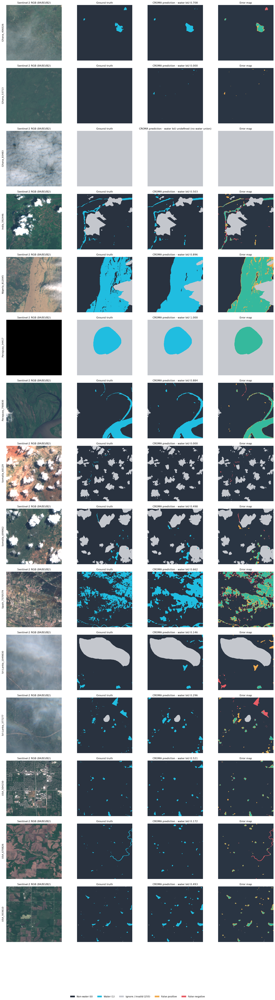

In [25]:

fig, axes, chip_ids = plot_predictions(
    predictions_dir=run_results_dir / "non_bol",
    hand_dir="dataset/sen1floods11_hand_labeled_only/HandLabeled",
    n=15,
    seed=42,
    save_path=run_results_dir / "croma_visualization_15.png",
    show_errors=True
)

plt.show()

split,non_bol,bol
test_loss,2.024988e-01,4.361886e-01
water_iou,7.051036e-01,5.344547e-01
nonwater_iou,9.471955e-01,8.879053e-01
miou,8.261495e-01,7.111800e-01
precision,7.677172e-01,6.757078e-01
recall,8.963236e-01,7.188368e-01
f1,8.270507e-01,6.966054e-01
omission_error,1.036764e-01,2.811632e-01
commission_error,2.322828e-01,3.242922e-01
accuracy,9.531150e-01,9.006857e-01


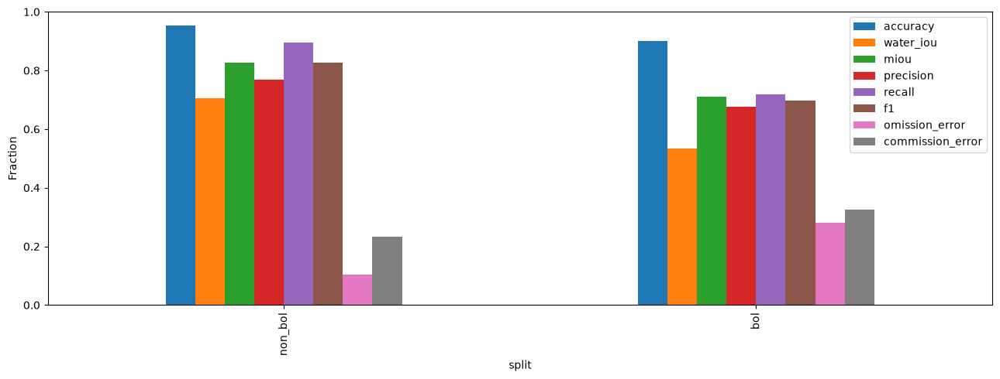

split,non_bol_original,bol_original,non_bol_usable_s2_images,bol_usable_s2_images
test_loss,2.024988e-01,4.361886e-01,NaN,NaN
water_iou,7.051036e-01,5.344547e-01,7.005106e-01,5.344547e-01
nonwater_iou,9.471955e-01,8.879053e-01,9.471955e-01,8.879053e-01
miou,8.261495e-01,7.111800e-01,8.238531e-01,7.111800e-01
precision,7.677172e-01,6.757078e-01,7.637728e-01,6.757078e-01
recall,8.963236e-01,7.188368e-01,8.942623e-01,7.188368e-01
f1,8.270507e-01,6.966054e-01,8.238827e-01,6.966054e-01
omission_error,1.036764e-01,2.811632e-01,1.057377e-01,2.811632e-01
commission_error,2.322828e-01,3.242922e-01,2.362272e-01,3.242922e-01
accuracy,9.531150e-01,9.006857e-01,9.530004e-01,9.006857e-01


In [26]:
# Recompute from confusion counts so this also works with previously saved metric dictionaries.
for metrics in (metrics_nonbolivia, metrics_bolivia):
    metrics.update(binary_metrics(*(metrics[key] for key in ("TP", "FP", "FN", "TN"))))
# Water precision/recall use water as the positive class; commission = FP/(TP+FP).
all_metrics = metric_table({"non_bol": metrics_nonbolivia, "bol": metrics_bolivia}, run_results_dir)
display(all_metrics.T)
all_metrics[["accuracy", "water_iou", "miou", "precision", "recall", "f1",
             "omission_error", "commission_error"]].plot.bar(figsize=(13, 5), ylim=(0, 1))
plt.ylabel("Fraction")
plt.tight_layout()
plt.savefig(run_results_dir / "all_metrics_comparison.png", dpi=160)
plt.show()

# Report the original split above and the usable-optical subset separately.
usable_rows = []
for split, pairs in [("non_bol", test_data_non_bolivia), ("bol", test_data_bolivia)]:
    totals = np.zeros(4, dtype=np.int64)
    excluded = []
    for x_path, y_path in pairs:
        raw, label = load_image_pair((x_path, y_path))
        if not np.isfinite(raw).all(axis=0).any():
            excluded.append(x_path.name)
            continue
        with rasterio.open(run_results_dir / split / (x_path.stem + "_prediction.tif")) as src:
            pred = src.read(1)
        valid = np.isin(label, [0, 1])
        totals += [np.count_nonzero(valid & (pred == p) & (label == t))
                   for p, t in [(1, 1), (1, 0), (0, 1), (0, 0)]]
    usable_rows.append({"split": split, "included_images": len(pairs)-len(excluded),
                        "excluded_missing_s2_images": len(excluded),
                        **binary_metrics(*totals)})
    (run_results_dir / split / "excluded_missing_s2.json").write_text(json.dumps(excluded, indent=2))
usable_summary = pd.DataFrame(usable_rows)
usable_summary.to_csv(run_results_dir / "usable_s2_summary.csv", index=False)
input_quality_comparison = metric_table({
    "non_bol_original": metrics_nonbolivia,
    "non_bol_usable_s2_images": usable_summary.set_index("split").loc["non_bol"].to_dict(),
    "bol_original": metrics_bolivia,
    "bol_usable_s2_images": usable_summary.set_index("split").loc["bol"].to_dict(),
}, run_results_dir / "input_quality_comparison")
display(input_quality_comparison.T)
